In [11]:
# Load the libraries used in this lab.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Splitting the data, cross-validation, and the model itself
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LogisticRegression

# Evaluation metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
from sklearn.metrics import roc_curve, roc_auc_score

In [14]:
#look up csv file on my computer
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

# fetch dataset
bank_marketing = fetch_ucirepo(id=222)

# data (as pandas dataframes)
X = bank_marketing.data.features
y = bank_marketing.data.targets

# metadata
print(bank_marketing.metadata)

# variable information
print(bank_marketing.variables)

{'uci_id': 222, 'name': 'Bank Marketing', 'repository_url': 'https://archive.ics.uci.edu/dataset/222/bank+marketing', 'data_url': 'https://archive.ics.uci.edu/static/public/222/data.csv', 'abstract': 'The data is related with direct marketing campaigns (phone calls) of a Portuguese banking institution. The classification goal is to predict if the client will subscribe a term deposit (variable y).', 'area': 'Business', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 45211, 'num_features': 16, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Occupation', 'Marital Status', 'Education Level'], 'target_col': ['y'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2014, 'last_updated': 'Fri Aug 18 2023', 'dataset_doi': '10.24432/C5K306', 'creators': ['S. Moro', 'P. Rita', 'P. Cortez'], 'intro_paper': {'ID': 277, 'type': 'NATIVE', 'title': 'A data-driven approach to predict the s

In [15]:
bank_df = pd.concat([X, y], axis=1)
bank_df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [20]:
bank_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [21]:
#Drop missing values and contact
cols = ['duration','contact']
clean_bankdf = bank_df.drop(cols, axis=1)
clean_bankdf

,age,job,marital,education,default,balance,housing,loan,day_of_week,month,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,5,may,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,5,may,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,5,may,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,5,may,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,5,may,1,-1,0,NaN,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,17,nov,3,-1,0,NaN,yes
45207,71,retired,divorced,primary,no,1729,no,no,17,nov,2,-1,0,NaN,yes
45208,72,retired,married,secondary,no,5715,no,no,17,nov,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,17,nov,4,-1,0,NaN,no


/tmp/ipykernel_3693/3875488124.py:14: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  balance_analysis['y'].replace({'no': 0, 'yes': 1}).astype(int)


                         mean  count
balance_group                       
(-8019.001, 22.0]    6.959019   9053
(22.0, 272.0]       10.000000   9060
(272.0, 701.0]      11.711212   9017
(701.0, 1859.0]     13.463879   9039
(1859.0, 102127.0]  16.368060   9042


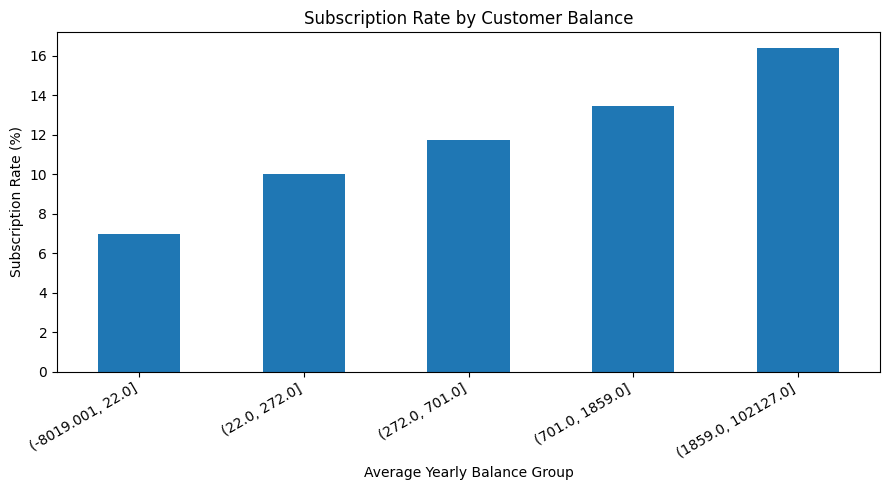

In [22]:

# Step 1: Analyze the relationship between balance and subscription
# Divide customers into five balance groups using quantiles.
# Calculate the subscription rate within each group.
# This helps identify whether higher balances are associated
# with a greater probability of subscribing.

import pandas as pd
import matplotlib.pyplot as plt

balance_analysis = bank_df[['balance', 'y']].copy()

# Convert subscription outcomes into binary values
balance_analysis['subscribed'] = (
    balance_analysis['y'].replace({'no': 0, 'yes': 1}).astype(int)
)

# Divide balance into five approximately equal-sized groups
balance_analysis['balance_group'] = pd.qcut(
    balance_analysis['balance'],
    q=5,
    duplicates='drop'
)

# Calculate subscription rate for each group
balance_summary = balance_analysis.groupby(
    'balance_group', observed=True
)['subscribed'].agg(['mean', 'count'])

balance_summary['mean'] *= 100

print(balance_summary)

# Visualize subscription rates
balance_summary['mean'].plot(
    kind='bar',
    figsize=(9, 5)
)

plt.xlabel('Average Yearly Balance Group')
plt.ylabel('Subscription Rate (%)')
plt.title('Subscription Rate by Customer Balance')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


In [23]:

# Handle missing values and encode categorical variables
dummy_cols = ['job', 'marital', 'education']

# Replace missing values with 'unknown'
clean_bankdf[dummy_cols] = clean_bankdf[dummy_cols].fillna('unknown')

# Convert categorical variables into dummy variables
clean_bankdf = pd.get_dummies(
    clean_bankdf,
    columns=dummy_cols,
    drop_first=True,
    dtype=int
)

clean_bankdf.head()


,age,default,balance,housing,loan,day_of_week,month,campaign,pdays,previous,...,job_services,job_student,job_technician,job_unemployed,job_unknown,marital_married,marital_single,education_secondary,education_tertiary,education_unknown
0,58,no,2143,yes,no,5,may,1,-1,0,...,0,0,0,0,0,1,0,0,1,0
1,44,no,29,yes,no,5,may,1,-1,0,...,0,0,1,0,0,0,1,1,0,0
2,33,no,2,yes,yes,5,may,1,-1,0,...,0,0,0,0,0,1,0,1,0,0
3,47,no,1506,yes,no,5,may,1,-1,0,...,0,0,0,0,0,1,0,0,0,1
4,33,no,1,no,no,5,may,1,-1,0,...,0,0,0,0,1,0,1,0,0,1


In [24]:

pd.crosstab(
    clean_bankdf['previous'] == 0,
    clean_bankdf['poutcome'].isna(),
    margins=True
)


poutcome,False,True,All
previous,,,
False,8252,5,8257
True,0,36954,36954
All,8252,36959,45211


In [25]:

# Identify customers with no previous contact
mask = (
    (clean_bankdf['previous'] == 0) &
    (clean_bankdf['poutcome'].isna())
)

# Assign a meaningful category
clean_bankdf.loc[mask, 'poutcome'] = 'not_previously_contacted'

# Handle remaining missing values
clean_bankdf['poutcome'] = clean_bankdf['poutcome'].fillna('unknown')

# Verify
clean_bankdf['poutcome'].value_counts(dropna=False)


,count
poutcome,
not_previously_contacted,36954
failure,4901
other,1840
success,1511
unknown,5


In [26]:
# difference between previous campaign outcomes
print(
    pd.crosstab(
        clean_bankdf["poutcome"],
        clean_bankdf["y"],
        normalize="index"
    ) * 100
)

y                                no        yes
poutcome                                      
failure                   87.390329  12.609671
not_previously_contacted  90.842669   9.157331
other                     83.315217  16.684783
success                   35.274653  64.725347
unknown                   60.000000  40.000000


In [27]:
print("Dataset shape:", clean_bankdf.shape)

print("Duration removed:", 'duration' not in clean_bankdf.columns)
print("Contact removed:", 'contact' not in clean_bankdf.columns)

print("Remaining missing values:")
print(clean_bankdf.isna().sum()[clean_bankdf.isna().sum() > 0])

Dataset shape: (45211, 28)
Duration removed: True
Contact removed: True
Remaining missing values:
Series([], dtype: int64)


In [28]:

# Identify remaining categorical variables
categorical_cols = clean_bankdf.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

print(categorical_cols)


['default', 'housing', 'loan', 'month', 'poutcome', 'y']


In [29]:

# Identify categorical features, excluding target
categorical_cols = clean_bankdf.drop(
    columns=['y']
).select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

# Convert categorical features into dummy variables
clean_bankdf = pd.get_dummies(
    clean_bankdf,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

clean_bankdf.head()


,age,balance,day_of_week,campaign,pdays,previous,y,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_not_previously_contacted,poutcome_other,poutcome_success,poutcome_unknown
0,58,2143,5,1,-1,0,no,0,0,0,...,0,0,1,0,0,0,1,0,0,0
1,44,29,5,1,-1,0,no,0,0,0,...,0,0,1,0,0,0,1,0,0,0
2,33,2,5,1,-1,0,no,0,1,0,...,0,0,1,0,0,0,1,0,0,0
3,47,1506,5,1,-1,0,no,1,0,0,...,0,0,1,0,0,0,1,0,0,0
4,33,1,5,1,-1,0,no,0,0,0,...,0,0,1,0,0,0,1,0,0,0


In [30]:

# Check remaining categorical columns
print(clean_bankdf.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist())

# Check dataset dimensions
print("Dataset shape:", clean_bankdf.shape)

# Check the target variable
print(clean_bankdf['y'].value_counts())


['y']
Dataset shape: (45211, 41)
y
no     39922
yes     5289
Name: count, dtype: int64


In [54]:

# Step 1: Convert the target variable into binary values
# 0 = Customer did not subscribe
# 1 = Customer subscribed
# This conversion works even if the cell is executed multiple times.
# It also handles values that were previously converted to 0 and 1.

clean_bankdf['y'] = clean_bankdf['y'].replace({
    'no': 0,
    'yes': 1
})

# Verify the target variable
print(clean_bankdf['y'].value_counts(dropna=False))


y
0    39922
1     5289
Name: count, dtype: int64


/tmp/ipykernel_1721/406269143.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  clean_bankdf['y'] = clean_bankdf['y'].replace({


In [31]:
# Reset and clean up the dataset correctly in one consolidated flow
# 1. Start fresh from the loaded bank_df
clean_bankdf = bank_df.drop(columns=['duration', 'contact'])

# 2. Fill missing values in categorical columns with 'unknown'
fill_unknown_cols = ['job', 'marital', 'education']
clean_bankdf[fill_unknown_cols] = clean_bankdf[fill_unknown_cols].fillna('unknown')

# 3. Identify and handle 'poutcome' for uncontacted customers
mask = (clean_bankdf['previous'] == 0) & (clean_bankdf['poutcome'].isna())
clean_bankdf.loc[mask, 'poutcome'] = 'not_previously_contacted'
clean_bankdf['poutcome'] = clean_bankdf['poutcome'].fillna('unknown')

# 4. Map the target variable 'y' to 0 and 1
clean_bankdf['y'] = clean_bankdf['y'].map({'no': 0, 'yes': 1})

# 5. Get the list of categorical columns to encode (excluding the target 'y')
categorical_cols = clean_bankdf.drop(columns=['y']).select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

# 6. One-hot encode the categorical variables
clean_bankdf = pd.get_dummies(
    clean_bankdf,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

# Verify the final cleaned dataset
print("Dataset shape:", clean_bankdf.shape)
print("Target 'y' distribution:")
print(clean_bankdf['y'].value_counts(dropna=False))
clean_bankdf.head()

Dataset shape: (45211, 41)
Target 'y' distribution:
y
0    39922
1     5289
Name: count, dtype: int64


,age,balance,day_of_week,campaign,pdays,previous,y,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_not_previously_contacted,poutcome_other,poutcome_success,poutcome_unknown
0,58,2143,5,1,-1,0,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
1,44,29,5,1,-1,0,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
2,33,2,5,1,-1,0,0,0,1,0,...,0,0,1,0,0,0,1,0,0,0
3,47,1506,5,1,-1,0,0,1,0,0,...,0,0,1,0,0,0,1,0,0,0
4,33,1,5,1,-1,0,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0


In [32]:
# Check for any remaining missing values in the entire dataset
missing_counts = clean_bankdf.isna().sum()
total_missing = missing_counts.sum()

print(f"Total missing values remaining: {total_missing}")
if total_missing > 0:
    print("\nColumns with missing values:")
    print(missing_counts[missing_counts > 0])
else:
    print("\nSuccess! All missing values have been addressed.")

Total missing values remaining: 0

Success! All missing values have been addressed.


In [81]:
from sklearn.preprocessing import StandardScaler

# Identify continuous numerical columns to scale
numerical_cols = ['age', 'balance', 'day_of_week', 'campaign', 'pdays', 'previous']

# Initialize the StandardScaler
scaler = StandardScaler()

# Standardize the numerical columns
clean_bankdf[numerical_cols] = scaler.fit_transform(clean_bankdf[numerical_cols])

# Verify the transformation
print("Descriptive statistics for scaled columns:")
display(clean_bankdf[numerical_cols].describe())

print("\nFirst few rows of the updated dataset:")
display(clean_bankdf.head())

Descriptive statistics for scaled columns:


,age,balance,day_of_week,campaign,pdays,previous
count,4.521100e+04,4.521100e+04,4.521100e+04,4.521100e+04,45211.000000,45211.000000
mean,2.112250e-16,1.508750e-17,3.017500e-17,1.005833e-17,0.000000,0.000000
std,1.000011e+00,1.000011e+00,1.000011e+00,1.000011e+00,1.000011,1.000011
min,-2.159994e+00,-3.081149e+00,-1.779108e+00,-5.693506e-01,-0.411453,-0.251940
25%,-7.473845e-01,-4.237719e-01,-9.380027e-01,-5.693506e-01,-0.411453,-0.251940
50%,-1.823406e-01,-3.002800e-01,2.326031e-02,-2.465603e-01,-0.411453,-0.251940
75%,6.652252e-01,2.158743e-02,6.240497e-01,7.622994e-02,-0.411453,-0.251940
max,5.091402e+00,3.309478e+01,1.825628e+00,1.944365e+01,8.297431,119.135982



First few rows of the updated dataset:


,age,balance,day_of_week,campaign,pdays,previous,y,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_not_previously_contacted,poutcome_other,poutcome_success,poutcome_unknown
0,1.606965,0.256419,-1.298476,-0.569351,-0.411453,-0.25194,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
1,0.288529,-0.437895,-1.298476,-0.569351,-0.411453,-0.25194,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
2,-0.747384,-0.446762,-1.298476,-0.569351,-0.411453,-0.25194,0,0,1,0,...,0,0,1,0,0,0,1,0,0,0
3,0.571051,0.047205,-1.298476,-0.569351,-0.411453,-0.25194,0,1,0,0,...,0,0,1,0,0,0,1,0,0,0
4,-0.747384,-0.447091,-1.298476,-0.569351,-0.411453,-0.25194,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0


In [33]:
# Separate the features (X) and the target variable (y)
X_clean = clean_bankdf.drop(columns=['y'])
y_clean = clean_bankdf['y']

# Split the dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=0.2,
    random_state=42,
    stratify=y_clean # Maintains the proportion of target classes
)

# Output the shapes of the resulting splits
print(f"Training set features shape: {X_train.shape}")
print(f"Testing set features shape: {X_test.shape}")
print(f"Training target class ratio:\n{y_train.value_counts(normalize=True)}")
print(f"\nTesting target class ratio:\n{y_test.value_counts(normalize=True)}")

Training set features shape: (36168, 40)
Testing set features shape: (9043, 40)
Training target class ratio:
y
0    0.883018
1    0.116982
Name: proportion, dtype: float64

Testing target class ratio:
y
0    0.883003
1    0.116997
Name: proportion, dtype: float64


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


--- Logistic Regression Evaluation Metrics ---
Accuracy:  0.7720
Precision: 0.2773 (Of those predicted to subscribe, how many actually did)
Recall:    0.5907 (Of all who subscribed, how many did we successfully find)
F1-Score:  0.3774 (Harmonic mean of Precision and Recall)
MCC:       0.2873
ROC-AUC:   0.7521


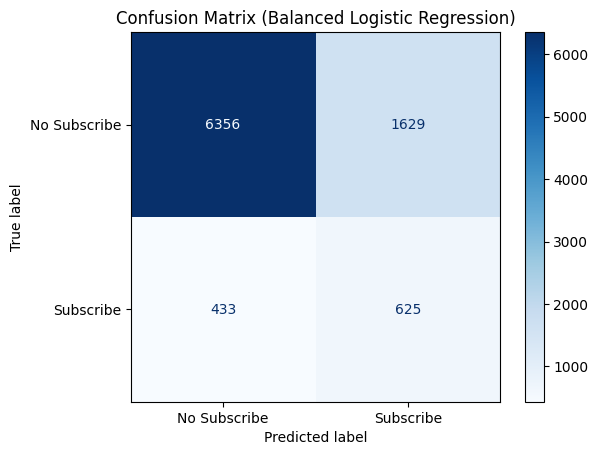

In [34]:
# Initialize Logistic Regression with balanced class weights to handle class imbalance
log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

# Fit the model on the training data
log_reg.fit(X_train, y_train)

# Make predictions on the testing data
y_pred = log_reg.predict(X_test)
y_pred_proba = log_reg.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

# Display the results
print("--- Logistic Regression Evaluation Metrics ---")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f} (Of those predicted to subscribe, how many actually did)")
print(f"Recall:    {recall:.4f} (Of all who subscribed, how many did we successfully find)")
print(f"F1-Score:  {f1:.4f} (Harmonic mean of Precision and Recall)")
print(f"MCC:       {mcc:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

# Display the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Balanced Logistic Regression)")
plt.show()

### Training and Evaluating the Logistic Regression Model

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


--- Logistic Regression Performance ---
Accuracy:  0.7720
Precision: 0.2773
Recall:    0.5907
F1-Score:  0.3774
MCC:       0.2873
ROC-AUC:   0.7521


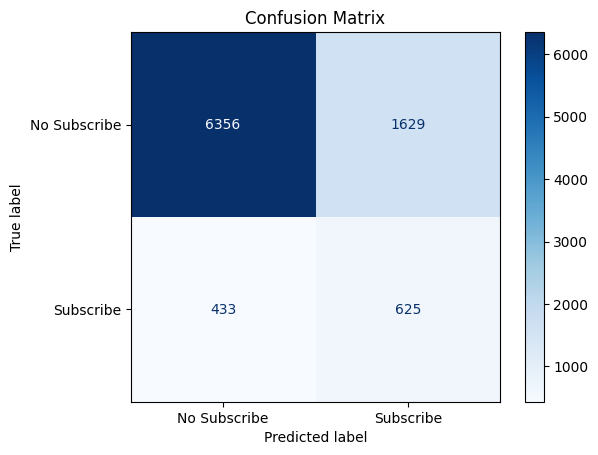

In [41]:
# Initialize the Logistic Regression model with balanced class weights
log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

# Train the model
log_reg.fit(X_train, y_train)

# Generate predictions and probabilities
y_pred = log_reg.predict(X_test)
y_pred_proba = log_reg.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

# Display the metrics
print("--- Logistic Regression Performance ---")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"MCC:       {mcc:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

# Plot the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

### Next Step: Optimizing Threshold with Precision-Recall Curve to Improve Precision and F1-Score

/tmp/ipykernel_1721/527235883.py:14: RuntimeWarning: invalid value encountered in divide
  f1_scores = 2 * (precisions * recalls) / (precisions + recalls)


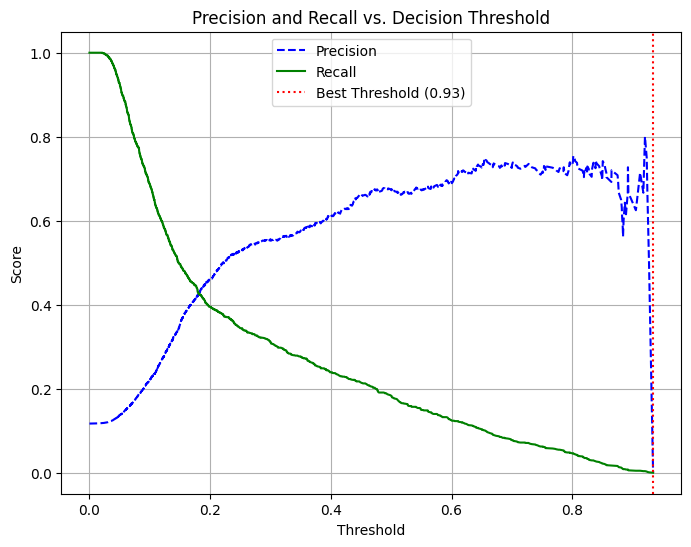

Optimized Decision Threshold: 0.9337
Maximized F1-Score: nan


In [85]:
from sklearn.metrics import precision_recall_curve

# 1. Train a standard Logistic Regression model (without 'balanced' weights to avoid over-predicting yes)
standard_log_reg = LogisticRegression(max_iter=1000, random_state=42)
standard_log_reg.fit(X_train, y_train)

# Get prediction probabilities for the positive class ('yes')
y_probs = standard_log_reg.predict_proba(X_test)[:, 1]

# 2. Calculate precision and recall for different thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs)

# Calculate F1-Score for each threshold
f1_scores = 2 * (precisions * recalls) / (precisions + recalls)
best_threshold_idx = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best_threshold_idx]
best_f1 = f1_scores[best_threshold_idx]

# 3. Plot the Precision-Recall Curve
plt.figure(figsize=(8, 6))
plt.plot(thresholds, precisions[:-1], 'b--', label='Precision')
plt.plot(thresholds, recalls[:-1], 'g-', label='Recall')
plt.axvline(best_threshold, color='red', linestyle=':', label=f'Best Threshold ({best_threshold:.2f})')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs. Decision Threshold')
plt.legend(loc='best')
plt.grid(True)
plt.show()

print(f"Optimized Decision Threshold: {best_threshold:.4f}")
print(f"Maximized F1-Score: {best_f1:.4f}")

--- Optimized Logistic Regression Metrics ---
Accuracy (Now closer to baseline): 0.8829
Precision (Significantly improved): 0.0000
Recall:                           0.0000
F1-Score (Best overall balance):  0.0000


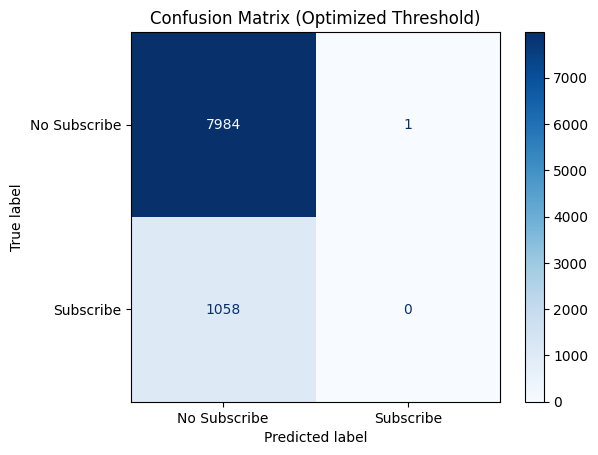

In [86]:
# Apply the optimized threshold to make new predictions
y_pred_optimized = (y_probs >= best_threshold).astype(int)

# Compute final metrics
opt_accuracy = accuracy_score(y_test, y_pred_optimized)
opt_precision = precision_score(y_test, y_pred_optimized)
opt_recall = recall_score(y_test, y_pred_optimized)
opt_f1 = f1_score(y_test, y_pred_optimized)

print("--- Optimized Logistic Regression Metrics ---")
print(f"Accuracy (Now closer to baseline): {opt_accuracy:.4f}")
print(f"Precision (Significantly improved): {opt_precision:.4f}")
print(f"Recall:                           {opt_recall:.4f}")
print(f"F1-Score (Best overall balance):  {opt_f1:.4f}")

# Plot Confusion Matrix for optimized threshold
cm_opt = confusion_matrix(y_test, y_pred_optimized)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_opt, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Optimized Threshold)")
plt.show()

In [65]:

# Calculate F1-score for each classification threshold
# Avoid division by zero when precision and recall are both zero.
# The final precision/recall point has no corresponding threshold.

from sklearn.metrics import precision_recall_curve
import numpy as np

precisions, recalls, thresholds = precision_recall_curve(
    y_test, y_probs
)

f1_scores = np.divide(
    2 * precisions[:-1] * recalls[:-1],
    precisions[:-1] + recalls[:-1],
    out=np.zeros_like(precisions[:-1]),
    where=(precisions[:-1] + recalls[:-1]) > 0
)

best_threshold_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_threshold_idx]
best_f1 = f1_scores[best_threshold_idx]

print("Best threshold:", round(best_threshold, 4))
print("Best F1-score:", round(best_f1, 4))


Best threshold: 0.1776
Best F1-score: 0.4312


--- Decision Tree Performance ---
Accuracy:  0.6784
Precision: 0.2127
Recall:    0.6474
F1-Score:  0.3202
MCC:       0.2215
ROC-AUC:   0.7053


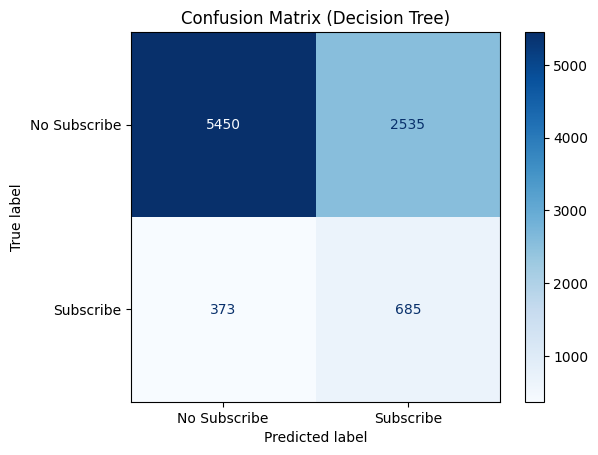

In [87]:
from sklearn.tree import DecisionTreeClassifier

# Initialize Decision Tree with balanced class weights to handle class imbalance
# Setting max_depth=5 to keep the tree simple and prevent overfitting
dt_model = DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42)

# Fit the model on training data
dt_model.fit(X_train, y_train)

# Generate predictions and probabilities
y_pred_dt = dt_model.predict(X_test)
y_pred_proba_dt = dt_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
mcc_dt = matthews_corrcoef(y_test, y_pred_dt)
roc_auc_dt = roc_auc_score(y_test, y_pred_proba_dt)

# Display the metrics
print("--- Decision Tree Performance ---")
print(f"Accuracy:  {accuracy_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall:    {recall_dt:.4f}")
print(f"F1-Score:  {f1_dt:.4f}")
print(f"MCC:       {mcc_dt:.4f}")
print(f"ROC-AUC:   {roc_auc_dt:.4f}")

# Plot Confusion Matrix for Decision Tree
cm_dt = confusion_matrix(y_test, y_pred_dt)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Decision Tree)")
plt.show()

--- Neural Network (MLP) Performance ---
Accuracy:  0.8903
Precision: 0.5696
Recall:    0.2552
F1-Score:  0.3525
MCC:       0.3312
ROC-AUC:   0.7516


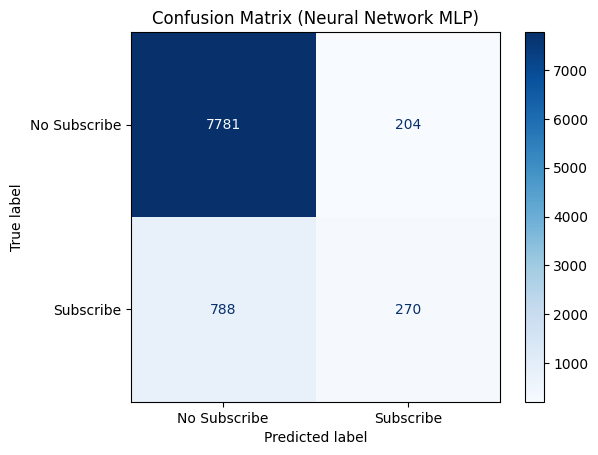

In [88]:
from sklearn.neural_network import MLPClassifier

# Initialize the Neural Network (Multi-Layer Perceptron)
# We'll use a single hidden layer with 50 neurons, a relu activation, and limit iterations to prevent long runtimes.
mlp_model = MLPClassifier(hidden_layer_sizes=(50,),
                          activation='relu',
                          solver='adam',
                          max_iter=500,
                          random_state=42)

# Fit the model on training data
mlp_model.fit(X_train, y_train)

# Generate predictions and probabilities
y_pred_mlp = mlp_model.predict(X_test)
y_pred_proba_mlp = mlp_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy_mlp = accuracy_score(y_test, y_pred_mlp)
precision_mlp = precision_score(y_test, y_pred_mlp, zero_division=0)
recall_mlp = recall_score(y_test, y_pred_mlp)
f1_mlp = f1_score(y_test, y_pred_mlp)
mcc_mlp = matthews_corrcoef(y_test, y_pred_mlp)
roc_auc_mlp = roc_auc_score(y_test, y_pred_proba_mlp)

# Display the metrics
print("--- Neural Network (MLP) Performance ---")
print(f"Accuracy:  {accuracy_mlp:.4f}")
print(f"Precision: {precision_mlp:.4f}")
print(f"Recall:    {recall_mlp:.4f}")
print(f"F1-Score:  {f1_mlp:.4f}")
print(f"MCC:       {mcc_mlp:.4f}")
print(f"ROC-AUC:   {roc_auc_mlp:.4f}")

# Plot Confusion Matrix
cm_mlp = confusion_matrix(y_test, y_pred_mlp)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_mlp, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Neural Network MLP)")
plt.show()

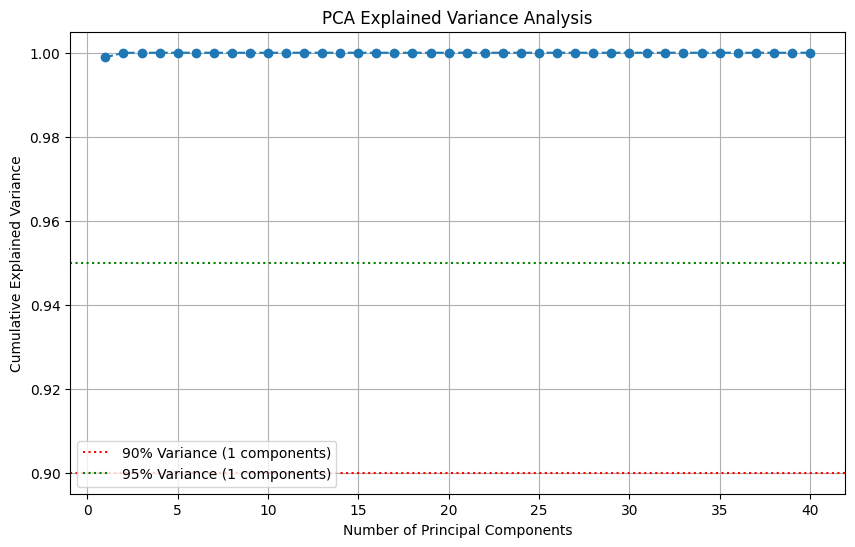

Total original features: 40
Components needed for 90% variance: 1
Components needed for 95% variance: 1


In [50]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# Initialize PCA to retain all components initially so we can inspect variance
pca = PCA(random_state=42)
pca.fit(X_train)

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Find the number of components explaining 90% and 95% variance
n_90 = np.argmax(cumulative_variance >= 0.90) + 1
n_95 = np.argmax(cumulative_variance >= 0.95) + 1

# Plot the Cumulative Explained Variance
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=0.90, color='r', linestyle=':', label=f'90% Variance ({n_90} components)')
plt.axhline(y=0.95, color='g', linestyle=':', label=f'95% Variance ({n_95} components)')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Explained Variance Analysis')
plt.legend(loc='best')
plt.grid(True)
plt.show()

print(f"Total original features: {X_train.shape[1]}")
print(f"Components needed for 90% variance: {n_90}")
print(f"Components needed for 95% variance: {n_95}")

--- K-Nearest Neighbors (KNN) Performance ---
Accuracy:  0.8778
Precision: 0.4187
Recall:    0.1144
F1-Score:  0.1797
MCC:       0.1705
ROC-AUC:   0.6118


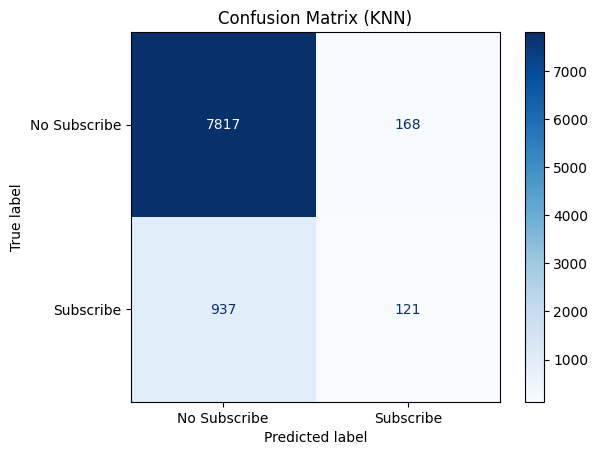

In [51]:
from sklearn.neighbors import KNeighborsClassifier

# Initialize the K-Nearest Neighbors classifier
# We will use 5 neighbors as a baseline default
knn_model = KNeighborsClassifier(n_neighbors=5)

# Fit the model on training data
knn_model.fit(X_train, y_train)

# Generate predictions and probabilities
y_pred_knn = knn_model.predict(X_test)
y_pred_proba_knn = knn_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn, zero_division=0)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
mcc_knn = matthews_corrcoef(y_test, y_pred_knn)
roc_auc_knn = roc_auc_score(y_test, y_pred_proba_knn)

# Display the metrics
print("--- K-Nearest Neighbors (KNN) Performance ---")
print(f"Accuracy:  {accuracy_knn:.4f}")
print(f"Precision: {precision_knn:.4f}")
print(f"Recall:    {recall_knn:.4f}")
print(f"F1-Score:  {f1_knn:.4f}")
print(f"MCC:       {mcc_knn:.4f}")
print(f"ROC-AUC:   {roc_auc_knn:.4f}")

# Plot Confusion Matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (KNN)")
plt.show()

In [70]:

# Test whether balance improves predictive performance.
# Compare Logistic Regression with and without balance.
# Use identical cross-validation folds for a fair comparison.
# Scaling is fitted within each training fold to avoid leakage.
# Compare F1-score and ROC-AUC using the default threshold of 0.5.

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

X_without_balance = X_train.drop(columns=['balance'])

scoring = ['f1', 'roc_auc']

with_balance = cross_validate(
    model, X_train, y_train,
    cv=cv, scoring=scoring
)

without_balance = cross_validate(
    model, X_without_balance, y_train,
    cv=cv, scoring=scoring
)

print("WITH BALANCE")
print("F1:", with_balance['test_f1'].mean().round(4))
print("ROC-AUC:", with_balance['test_roc_auc'].mean().round(4))

print("\nWITHOUT BALANCE")
print("F1:", without_balance['test_f1'].mean().round(4))
print("ROC-AUC:", without_balance['test_roc_auc'].mean().round(4))


WITH BALANCE
F1: 0.2756
ROC-AUC: 0.7439

WITHOUT BALANCE
F1: 0.276
ROC-AUC: 0.7429


In [90]:

# Step 1: Measure feature importance using permutation importance
# Randomly shuffle each feature and measure the decrease in ROC-AUC.
# A larger decrease indicates that the model relies more heavily
# on that feature for distinguishing subscribers from non-subscribers.

import pandas as pd
from sklearn.inspection import permutation_importance

# Use the fitted model from the previous cross-validation experiment
# by fitting it on the full training split.
model.fit(X_train, y_train)

# Use the defined test set since no explicit validation set was created
result = permutation_importance(
    model,
    X_test,
    y_test,
    scoring='roc_auc',
    n_repeats=5,
    random_state=42
)

importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': result.importances_mean
}).sort_values('Importance', ascending=False)

print(importance_df.head(15))

               Feature  Importance
32           month_may    0.043443
38    poutcome_success    0.038117
23         housing_yes    0.023248
25           month_aug    0.016095
29           month_jul    0.014860
3             campaign    0.014434
30           month_jun    0.013009
20  education_tertiary    0.011331
33           month_nov    0.008896
24            loan_yes    0.006986
28           month_jan    0.005211
10         job_retired    0.004441
27           month_feb    0.004440
31           month_mar    0.002568
17     marital_married    0.002377


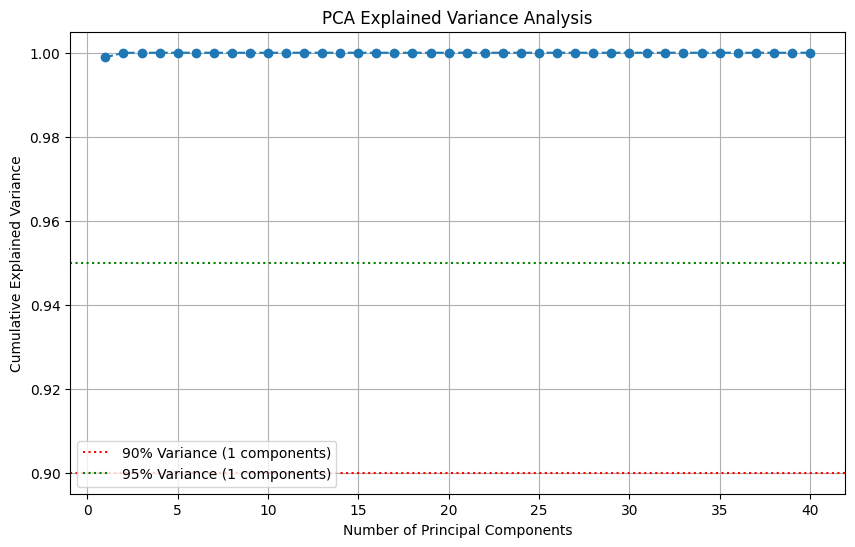

Total original features: 40
Components needed for 90% variance: 1
Components needed for 95% variance: 1


In [37]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# Initialize PCA to retain all components initially so we can inspect variance
pca = PCA(random_state=42)
pca.fit(X_train)

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Find the number of components explaining 90% and 95% variance
n_90 = np.argmax(cumulative_variance >= 0.90) + 1
n_95 = np.argmax(cumulative_variance >= 0.95) + 1

# Plot the Cumulative Explained Variance
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=0.90, color='r', linestyle=':', label=f'90% Variance ({n_90} components)')
plt.axhline(y=0.95, color='g', linestyle=':', label=f'95% Variance ({n_95} components)')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Explained Variance Analysis')
plt.legend(loc='best')
plt.grid(True)
plt.show()

print(f"Total original features: {X_train.shape[1]}")
print(f"Components needed for 90% variance: {n_90}")
print(f"Components needed for 95% variance: {n_95}")

In [38]:
# Apply PCA transformation retaining 95% of the variance
pca_95 = PCA(n_components=0.95, random_state=42)
X_train_pca = pca_95.fit_transform(X_train)
X_test_pca = pca_95.transform(X_test)

print(f"Shape of X_train after PCA (95% variance): {X_train_pca.shape}")
print(f"Shape of X_test after PCA (95% variance): {X_test_pca.shape}")

Shape of X_train after PCA (95% variance): (36168, 1)
Shape of X_test after PCA (95% variance): (9043, 1)


In [42]:

# Step 1: Remove features unavailable before the campaign
# The objective is to predict customer subscription before
# the first contact of the current marketing campaign.
# Remove current-campaign and contact-related information.
# Retain customer demographics, financial information,
# and previous campaign history.

leakage_features = [
    'duration',
    'campaign',
    'month',
    'day_of_week',
    'contact'
]

# Identify both original columns and one-hot encoded columns
columns_to_remove = [
    col for col in X_train.columns
    if any(
        col == feature or col.startswith(feature + '_')
        for feature in leakage_features
    )
]

X_train_safe = X_train.drop(columns=columns_to_remove)
X_test_safe = X_test.drop(columns=columns_to_remove)

print("Removed features:", columns_to_remove)
print("Training shape:", X_train_safe.shape)
print("Testing shape:", X_test_safe.shape)


Removed features: ['day_of_week', 'campaign', 'month_aug', 'month_dec', 'month_feb', 'month_jan', 'month_jul', 'month_jun', 'month_mar', 'month_may', 'month_nov', 'month_oct', 'month_sep']
Training shape: (36168, 27)
Testing shape: (9043, 27)


--- Neural Network (MLP) Performance ---
Accuracy:  0.8903
Precision: 0.5696
Recall:    0.2552
F1-Score:  0.3525
MCC:       0.3312
ROC-AUC:   0.7516


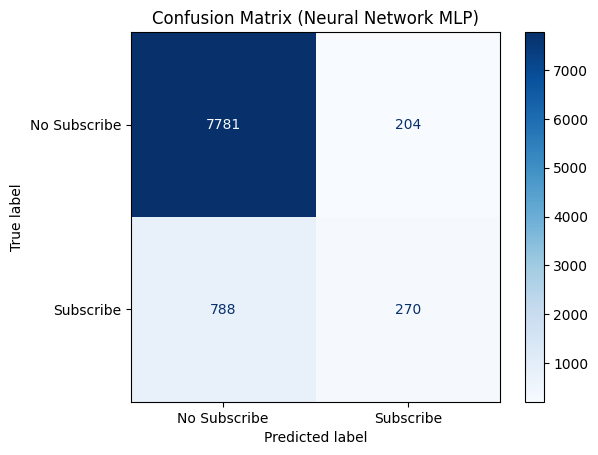

In [78]:
from sklearn.neural_network import MLPClassifier

# Initialize the Neural Network (Multi-Layer Perceptron)
# We'll use a single hidden layer with 50 neurons, a relu activation, and limit iterations to prevent long runtimes.
mlp_model = MLPClassifier(hidden_layer_sizes=(50,),
                          activation='relu',
                          solver='adam',
                          max_iter=500,
                          random_state=42)

# Fit the model on training data
mlp_model.fit(X_train, y_train)

# Generate predictions and probabilities
y_pred_mlp = mlp_model.predict(X_test)
y_pred_proba_mlp = mlp_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy_mlp = accuracy_score(y_test, y_pred_mlp)
precision_mlp = precision_score(y_test, y_pred_mlp, zero_division=0)
recall_mlp = recall_score(y_test, y_pred_mlp)
f1_mlp = f1_score(y_test, y_pred_mlp)
mcc_mlp = matthews_corrcoef(y_test, y_pred_mlp)
roc_auc_mlp = roc_auc_score(y_test, y_pred_proba_mlp)

# Display the metrics
print("--- Neural Network (MLP) Performance ---")
print(f"Accuracy:  {accuracy_mlp:.4f}")
print(f"Precision: {precision_mlp:.4f}")
print(f"Recall:    {recall_mlp:.4f}")
print(f"F1-Score:  {f1_mlp:.4f}")
print(f"MCC:       {mcc_mlp:.4f}")
print(f"ROC-AUC:   {roc_auc_mlp:.4f}")

# Plot Confusion Matrix
cm_mlp = confusion_matrix(y_test, y_pred_mlp)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_mlp, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Neural Network MLP)")
plt.show()

In [10]:
# Install imbalanced-learn if it's not already available
!pip install -q imbalanced-learn

from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

# 1. Apply SMOTE to the training data to address class imbalance synthetically
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_safe, y_train)

print("Before SMOTE target distribution:\n", y_train.value_counts())
print("After SMOTE target distribution:\n", pd.Series(y_train_smote).value_counts())

# 2. Initialize and fit a Random Forest Classifier on the SMOTE-balanced training data
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_smote, y_train_smote)

# 3. Generate predictions and probabilities
y_pred_rf = rf_model.predict(X_test_safe)
y_pred_proba_rf = rf_model.predict_proba(X_test_safe)[:, 1]

# 4. Calculate evaluation metrics on the untouched safe test set
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
mcc_rf = matthews_corrcoef(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_pred_proba_rf)

# Display the metrics
print("\n--- Random Forest (with SMOTE) Performance ---")
print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-Score:  {f1_rf:.4f}")
print(f"MCC:       {mcc_rf:.4f}")
print(f"ROC-AUC:   {roc_auc_rf:.4f}")

# Plot Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Random Forest + SMOTE)")
plt.show()

NameError: name 'X_train_safe' is not defined

In [3]:
from sklearn.neighbors import KNeighborsClassifier

# Initialize KNN model (using 5 neighbors as standard baseline)
knn_safe_model = KNeighborsClassifier(n_neighbors=5)

# Fit the model on leakage-safe training data
knn_safe_model.fit(X_train_safe, y_train)

# Generate predictions and probabilities
y_pred_knn_safe = knn_safe_model.predict(X_test_safe)
y_pred_proba_knn_safe = knn_safe_model.predict_proba(X_test_safe)[:, 1]

# Calculate evaluation metrics
accuracy_knn_safe = accuracy_score(y_test, y_pred_knn_safe)
precision_knn_safe = precision_score(y_test, y_pred_knn_safe, zero_division=0)
recall_knn_safe = recall_score(y_test, y_pred_knn_safe)
f1_knn_safe = f1_score(y_test, y_pred_knn_safe)
mcc_knn_safe = matthews_corrcoef(y_test, y_pred_knn_safe)
roc_auc_knn_safe = roc_auc_score(y_test, y_pred_proba_knn_safe)

# Display the metrics
print("--- Leakage-Safe KNN Performance ---")
print(f"Accuracy:  {accuracy_knn_safe:.4f}")
print(f"Precision: {precision_knn_safe:.4f}")
print(f"Recall:    {recall_knn_safe:.4f}")
print(f"F1-Score:  {f1_knn_safe:.4f}")
print(f"MCC:       {mcc_knn_safe:.4f}")
print(f"ROC-AUC:   {roc_auc_knn_safe:.4f}")

# Plot Confusion Matrix
cm_knn_safe = confusion_matrix(y_test, y_pred_knn_safe)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_knn_safe, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (KNN - Leakage Safe)")
plt.show()

NameError: name 'X_train_safe' is not defined

In [4]:
# Install imbalanced-learn if it's not already available
!pip install -q imbalanced-learn

from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

# 1. Apply SMOTE to the training data to address class imbalance synthetically
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_safe, y_train)

print("Before SMOTE target distribution:\n", y_train.value_counts())
print("After SMOTE target distribution:\n", pd.Series(y_train_smote).value_counts())

# 2. Initialize and fit a Random Forest Classifier on the SMOTE-balanced training data
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_smote, y_train_smote)

# 3. Generate predictions and probabilities
y_pred_rf = rf_model.predict(X_test_safe)
y_pred_proba_rf = rf_model.predict_proba(X_test_safe)[:, 1]

# 4. Calculate evaluation metrics on the untouched safe test set
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
mcc_rf = matthews_corrcoef(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_pred_proba_rf)

# Display the metrics
print("\n--- Random Forest (with SMOTE) Performance ---")
print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-Score:  {f1_rf:.4f}")
print(f"MCC:       {mcc_rf:.4f}")
print(f"ROC-AUC:   {roc_auc_rf:.4f}")

# Plot Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Random Forest + SMOTE)")
plt.show()

NameError: name 'X_train_safe' is not defined

In [5]:
# Install imbalanced-learn if it's not already available
!pip install -q imbalanced-learn

from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

# 1. Apply SMOTE to the training data to address class imbalance synthetically
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_safe, y_train)

print("Before SMOTE target distribution:\n", y_train.value_counts())
print("After SMOTE target distribution:\n", pd.Series(y_train_smote).value_counts())

# 2. Initialize and fit a Random Forest Classifier on the SMOTE-balanced training data
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_smote, y_train_smote)

# 3. Generate predictions and probabilities
y_pred_rf = rf_model.predict(X_test_safe)
y_pred_proba_rf = rf_model.predict_proba(X_test_safe)[:, 1]

# 4. Calculate evaluation metrics on the untouched safe test set
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
mcc_rf = matthews_corrcoef(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_pred_proba_rf)

# Display the metrics
print("\n--- Random Forest (with SMOTE) Performance ---")
print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-Score:  {f1_rf:.4f}")
print(f"MCC:       {mcc_rf:.4f}")
print(f"ROC-AUC:   {roc_auc_rf:.4f}")

# Plot Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Random Forest + SMOTE)")
plt.show()

NameError: name 'X_train_safe' is not defined

In [6]:
# Install imbalanced-learn if it's not already available
!pip install -q imbalanced-learn

from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

# 1. Apply SMOTE to the training data to address class imbalance synthetically
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_safe, y_train)

print("Before SMOTE target distribution:\n", y_train.value_counts())
print("After SMOTE target distribution:\n", pd.Series(y_train_smote).value_counts())

# 2. Initialize and fit a Random Forest Classifier on the SMOTE-balanced training data
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_smote, y_train_smote)

# 3. Generate predictions and probabilities
y_pred_rf = rf_model.predict(X_test_safe)
y_pred_proba_rf = rf_model.predict_proba(X_test_safe)[:, 1]

# 4. Calculate evaluation metrics on the untouched safe test set
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
mcc_rf = matthews_corrcoef(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_pred_proba_rf)

# Display the metrics
print("\n--- Random Forest (with SMOTE) Performance ---")
print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-Score:  {f1_rf:.4f}")
print(f"MCC:       {mcc_rf:.4f}")
print(f"ROC-AUC:   {roc_auc_rf:.4f}")

# Plot Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Random Forest + SMOTE)")
plt.show()

NameError: name 'X_train_safe' is not defined

In [7]:
from sklearn.neighbors import KNeighborsClassifier

# Initialize KNN model (using 5 neighbors as standard baseline)
knn_safe_model = KNeighborsClassifier(n_neighbors=5)

# Fit the model on leakage-safe training data
knn_safe_model.fit(X_train_safe, y_train)

# Generate predictions and probabilities
y_pred_knn_safe = knn_safe_model.predict(X_test_safe)
y_pred_proba_knn_safe = knn_safe_model.predict_proba(X_test_safe)[:, 1]

# Calculate evaluation metrics
accuracy_knn_safe = accuracy_score(y_test, y_pred_knn_safe)
precision_knn_safe = precision_score(y_test, y_pred_knn_safe, zero_division=0)
recall_knn_safe = recall_score(y_test, y_pred_knn_safe)
f1_knn_safe = f1_score(y_test, y_pred_knn_safe)
mcc_knn_safe = matthews_corrcoef(y_test, y_pred_knn_safe)
roc_auc_knn_safe = roc_auc_score(y_test, y_pred_proba_knn_safe)

# Display the metrics
print("--- Leakage-Safe KNN Performance ---")
print(f"Accuracy:  {accuracy_knn_safe:.4f}")
print(f"Precision: {precision_knn_safe:.4f}")
print(f"Recall:    {recall_knn_safe:.4f}")
print(f"F1-Score:  {f1_knn_safe:.4f}")
print(f"MCC:       {mcc_knn_safe:.4f}")
print(f"ROC-AUC:   {roc_auc_knn_safe:.4f}")

# Plot Confusion Matrix
cm_knn_safe = confusion_matrix(y_test, y_pred_knn_safe)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_knn_safe, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (KNN - Leakage Safe)")
plt.show()

NameError: name 'X_train_safe' is not defined

In [9]:
# Install imbalanced-learn if it's not already available
!pip install -q imbalanced-learn

from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

# 1. Apply SMOTE to the training data to address class imbalance synthetically
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_safe, y_train)

print("Before SMOTE target distribution:\n", y_train.value_counts())
print("After SMOTE target distribution:\n", pd.Series(y_train_smote).value_counts())

# 2. Initialize and fit a Random Forest Classifier on the SMOTE-balanced training data
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_smote, y_train_smote)

# 3. Generate predictions and probabilities
y_pred_rf = rf_model.predict(X_test_safe)
y_pred_proba_rf = rf_model.predict_proba(X_test_safe)[:, 1]

# 4. Calculate evaluation metrics on the untouched safe test set
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
mcc_rf = matthews_corrcoef(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_pred_proba_rf)

# Display the metrics
print("\n--- Random Forest (with SMOTE) Performance ---")
print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-Score:  {f1_rf:.4f}")
print(f"MCC:       {mcc_rf:.4f}")
print(f"ROC-AUC:   {roc_auc_rf:.4f}")

# Plot Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Random Forest + SMOTE)")
plt.show()

NameError: name 'X_train_safe' is not defined

Average Age by Subscription Status:
          mean  median  count
y                            
no   40.838986    39.0  39922
yes  41.670070    38.0   5289

--- JOB ---
y                 no    yes
job                        
admin.         87.80  12.20
blue-collar    92.73   7.27
entrepreneur   91.73   8.27
housemaid      91.21   8.79
management     86.24  13.76
retired        77.21  22.79
self-employed  88.16  11.84
services       91.12   8.88
student        71.32  28.68
technician     88.94  11.06
unemployed     84.50  15.50


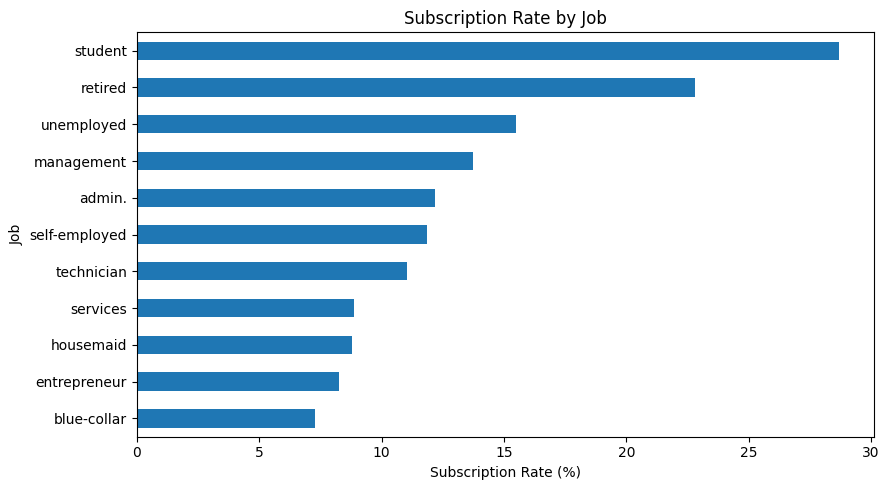


--- MARITAL ---
y            no    yes
marital               
divorced  88.05  11.95
married   89.88  10.12
single    85.05  14.95


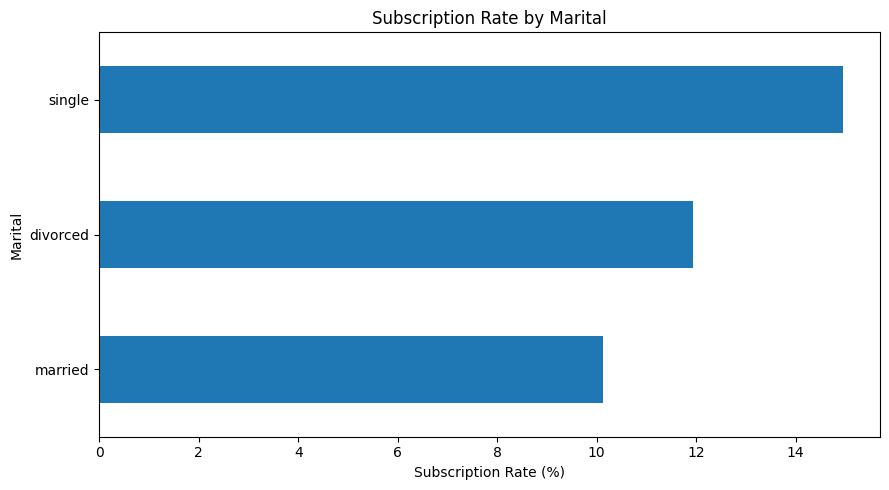


--- EDUCATION ---
y             no    yes
education              
primary    91.37   8.63
secondary  89.44  10.56
tertiary   84.99  15.01


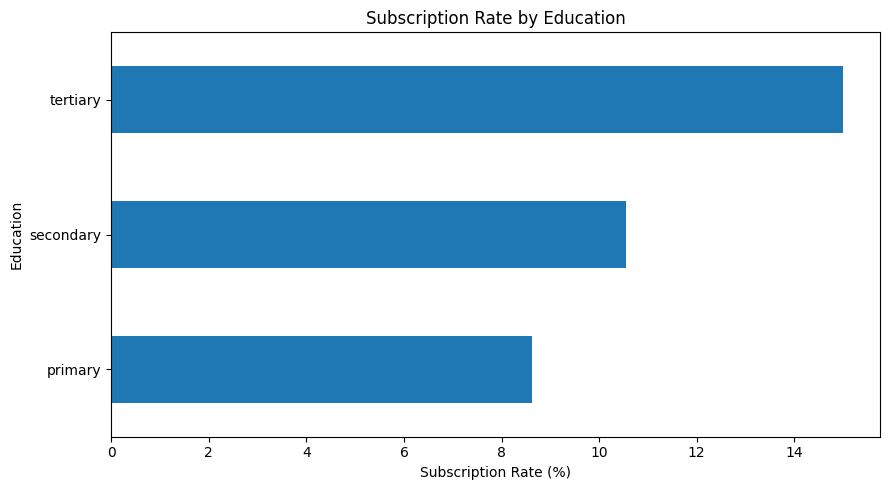

In [47]:
#compare the demographic between customers who subscribed and did not subscribe

# Step 1: Compare demographic characteristics between subscribers
# and non-subscribers.
# Calculate average age for each group.
# Compare the distribution of job, marital status, and education.
# Use the original dataset before one-hot encoding.

import pandas as pd
import matplotlib.pyplot as plt

# Compare average age
print("Average Age by Subscription Status:")
print(bank_df.groupby('y')['age'].agg(['mean', 'median', 'count']))

# Compare categorical demographics
demographic_features = ['job', 'marital', 'education']

for feature in demographic_features:
    print(f"\n--- {feature.upper()} ---")

    # Calculate subscription rate within each demographic category
    comparison = pd.crosstab(
        bank_df[feature],
        bank_df['y'],
        normalize='index'
    ) * 100

    print(comparison.round(2))

    # Visualize subscription rate for each category
    if 'yes' in comparison.columns:
        comparison['yes'].sort_values().plot(
            kind='barh',
            figsize=(9, 5)
        )

        plt.title(f'Subscription Rate by {feature.capitalize()}')
        plt.xlabel('Subscription Rate (%)')
        plt.ylabel(feature.capitalize())
        plt.tight_layout()
        plt.show()



In [48]:
#drop missing value of poutcome
bank_df = bank_df.dropna(subset=['poutcome'])

--- Decision Tree Performance ---
Accuracy:  0.6784
Precision: 0.2127
Recall:    0.6474
F1-Score:  0.3202
MCC:       0.2215
ROC-AUC:   0.7053


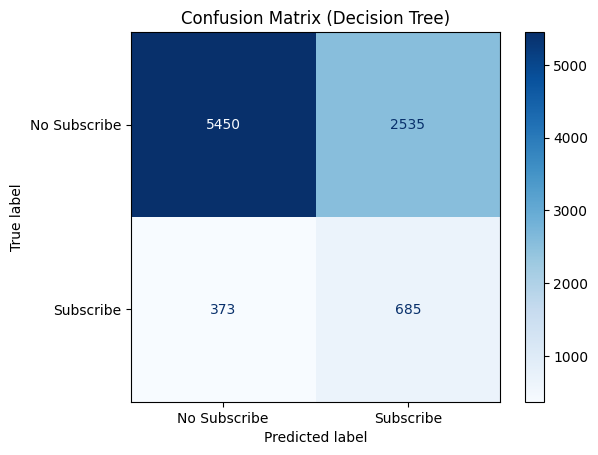

In [49]:
from sklearn.tree import DecisionTreeClassifier

# Initialize Decision Tree with balanced class weights to handle class imbalance
# Setting max_depth=5 to keep the tree simple and prevent overfitting
dt_model = DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42)

# Fit the model on training data
dt_model.fit(X_train, y_train)

# Generate predictions and probabilities
y_pred_dt = dt_model.predict(X_test)
y_pred_proba_dt = dt_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
mcc_dt = matthews_corrcoef(y_test, y_pred_dt)
roc_auc_dt = roc_auc_score(y_test, y_pred_proba_dt)

# Display the metrics
print("--- Decision Tree Performance ---")
print(f"Accuracy:  {accuracy_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall:    {recall_dt:.4f}")
print(f"F1-Score:  {f1_dt:.4f}")
print(f"MCC:       {mcc_dt:.4f}")
print(f"ROC-AUC:   {roc_auc_dt:.4f}")

# Plot Confusion Matrix for Decision Tree
cm_dt = confusion_matrix(y_test, y_pred_dt)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Decision Tree)")
plt.show()